# Question 6

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## (a) 

In [7]:
df = pd.read_csv('jokes.csv')
M = df.values.astype(float)          # NaN = missing
observed = ~np.isnan(M)
print("Matrix shape:", M.shape)
print(f"Fraction observed: {observed.mean():.4f}")
print(f"Avg rated jokes per user: {observed.sum(axis=1).mean():.2f}")

Matrix shape: (5000, 100)
Fraction observed: 0.7264
Avg rated jokes per user: 72.64


## (b) Train/test split + baselines

In [8]:
rng = np.random.default_rng(42)
rows, cols = np.where(observed)
test_idx = rng.choice(len(rows), size=int(0.1 * len(rows)), replace=False)
test_r, test_c = rows[test_idx], cols[test_idx]
y_test = M[test_r, test_c]

M_train = M.copy()
M_train[test_r, test_c] = np.nan

def rmse(pred):
    return np.sqrt(np.mean((pred - y_test) ** 2))

global_mean = np.nanmean(M_train)
joke_mean = np.nanmean(M_train, axis=0)
user_mean = np.nanmean(M_train, axis=1)
joke_mean = np.where(np.isnan(joke_mean), global_mean, joke_mean)
user_mean = np.where(np.isnan(user_mean), global_mean, user_mean)

results = {
    'Global mean': rmse(np.full_like(y_test, global_mean)),
    'Joke mean': rmse(joke_mean[test_c]),
    'User mean': rmse(user_mean[test_r]),
}
for k, v in results.items():
    print(f"{k:12s} RMSE: {v:.4f}")

Global mean  RMSE: 5.2311
Joke mean    RMSE: 4.9839
User mean    RMSE: 4.6265


## (c) SVD on user-mean filled matrix

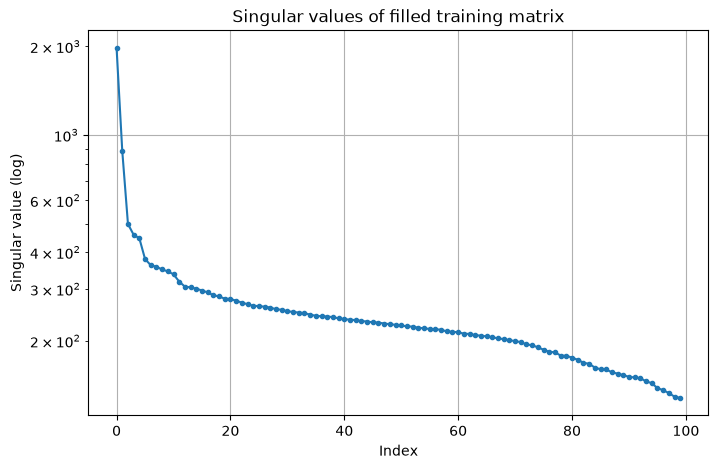

k= 2 RMSE: 4.2844
k= 5 RMSE: 4.1564
k=10 RMSE: 4.1154
k=20 RMSE: 4.1760
k=40 RMSE: 4.3495
Best k: 10


In [9]:
M_filled = np.where(np.isnan(M_train), user_mean[:, None], M_train)
U, s, Vt = np.linalg.svd(M_filled, full_matrices=False)

plt.figure(figsize=(8, 5))
plt.plot(s, marker='o', markersize=3)
plt.yscale('log')
plt.title('Singular values of filled training matrix')
plt.xlabel('Index')
plt.ylabel('Singular value (log)')
plt.grid(True)
plt.show()

preds = {}
for k in [2, 5, 10, 20, 40]:
    M_k = np.clip(U[:, :k] @ np.diag(s[:k]) @ Vt[:k], -10, 10)
    preds[k] = M_k
    results[f'SVD k={k}'] = rmse(M_k[test_r, test_c])
    print(f"k={k:2d} RMSE: {results[f'SVD k={k}']:.4f}")

best_k = min([2, 5, 10, 20, 40], key=lambda k: results[f'SVD k={k}'])
print("Best k:", best_k)

## (d) Recommendation for one user

In [10]:
test_df = pd.DataFrame({'user': test_r, 'joke': test_c, 'true': y_test})
counts = test_df['user'].value_counts()
user = counts[counts >= 5].index[0]

u = test_df[test_df['user'] == user].copy()
u['predicted'] = preds[best_k][user, u['joke']]
u['joke'] = df.columns[u['joke']]
u = u.sort_values('predicted', ascending=False)
print(f"User {user}, {len(u)} held-out ratings:")
print(u[['joke', 'predicted', 'true']].round(2).to_string(index=False))
print("Recommend first:", u.iloc[0]['joke'])

User 4287, 24 held-out ratings:
   joke  predicted  true
joke_07       3.32 -8.98
joke_11       2.18  7.28
joke_40       0.65 -5.39
joke_49      -0.08  6.60
joke_12      -0.30 -5.34
joke_56      -0.31 -5.39
joke_02      -0.87  5.58
joke_62      -0.88  3.79
joke_38      -1.06 -2.52
joke_98      -1.24 -0.15
joke_45      -1.52 -5.19
joke_87      -1.60  0.10
joke_79      -2.48 -8.06
joke_90      -2.54 -6.84
joke_71      -3.02 -5.58
joke_94      -3.27 -5.78
joke_99      -3.28 -6.65
joke_64      -3.43 -8.64
joke_86      -3.46  0.34
joke_63      -3.88 -9.56
joke_15      -4.09 -8.30
joke_30      -4.19 -6.36
joke_37      -5.50 -6.41
joke_16      -6.10 -8.25
Recommend first: joke_07


The recommender would suggest **joke_07** first, but the user actually rated it -8.98, so this one is a miss. Overall the ranking is roughly right, most jokes predicted low (bottom half) were truly rated very negative, so the model mostly gets which jokes this user dislikes. The predictions are also squished toward the user's mean, so it can't capture the strong +7 / -9 ratings well.

In [11]:
# Summary of all models on the held-out set
summary = pd.DataFrame({'Model': list(results.keys()), 'Test RMSE': list(results.values())})
print(summary.sort_values('Test RMSE').round(4).to_string(index=False))

      Model  Test RMSE
   SVD k=10     4.1154
    SVD k=5     4.1564
   SVD k=20     4.1760
    SVD k=2     4.2844
   SVD k=40     4.3495
  User mean     4.6265
  Joke mean     4.9839
Global mean     5.2311


## (e) Discussion
"Low rank" means each user's ratings can be explained by a small number of hidden factors, so the 5000x100 matrix is approximated by only k=10 user and joke factors. The SVD model did improve over the baselines. One limitation is that we fill the missing entries with the user mean before SVD, so the model treats those fake values as real ratings and gets biased toward the mean.